In [1]:
import pandas as pd 
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr, spearmanr
import random
from scipy import stats
import matplotlib.pyplot as plt

figure_dir="/home/jhu/jkim789/projects_aphill27/projects/pooch/figures"

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
import seaborn as sns
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

In [2]:
df_chrx = pd.read_csv("/path/to/project/pooch/findings/xist/chrX_promoter.methylation.bed", sep ='\t',
                      names = ["chr","start","end" , "cpg_count","total",'meth','sample','hap'])
df_chrx['hap'] = df_chrx['hap'].replace({1 : "Paternal", 2:"Maternal"})
df_chrx['frac']= df_chrx['meth'] / df_chrx['total']
df_chrx['frac_corrected']= df_chrx['meth'] / df_chrx['total']

swap_samples  = ["HG03579", "HG02717", "HG02451"]
swap_samples = [""]

df_chrx.loc[(df_chrx['sample'].isin(swap_samples)) & (df_chrx['hap']==2), "frac_corrected"] = df_chrx.loc[(df_chrx['sample'].isin(swap_samples)) & (df_chrx['hap']==1), "frac"]
df_chrx.loc[(df_chrx['sample'].isin(swap_samples)) & (df_chrx['hap']==1), "frac_corrected"] = df_chrx.loc[(df_chrx['sample'].isin(swap_samples)) & (df_chrx['hap']==2), "frac"]

df_chrx['id'] = df_chrx['chr'] + ":" + df_chrx['start'].astype(str) + "-" + df_chrx['end'].astype(str)

df_chrx_avg_cpg_count = df_chrx.groupby('id').agg(cpg_count  = ('cpg_count','mean')).reset_index()
df_chrx = df_chrx.loc[df_chrx['id'].isin(df_chrx_avg_cpg_count.loc[df_chrx_avg_cpg_count['cpg_count'] > 5 ,'id'])]

df_chrx = df_chrx.loc[df_chrx['start'] == 72285969]
del df_chrx['cpg_count']
del df_chrx['frac']
df_chrx.head(2)

,chr,start,end,total,meth,sample,hap,frac_corrected,id
1256,chrX,72285969,72286319,227,89,HG00408,Paternal,0.392070,chrX:72285969-72286319
3887,chrX,72285969,72286319,163,92,HG00408,Maternal,0.564417,chrX:72285969-72286319


In [3]:
df_wide = df_chrx.pivot_table(
    index=["sample", "id"],
    columns="hap",
    values="frac_corrected",
    aggfunc="mean"
).reset_index()
df_wide['diff'] = df_wide['Maternal'] - df_wide['Paternal']


df_wide.head(5)

hap,sample,id,Maternal,Paternal,diff
0,HG00408,chrX:72285969-72286319,0.564417,0.392070,0.172347
1,HG00423,chrX:72285969-72286319,0.447761,0.579832,-0.132071
2,HG00438,chrX:72285969-72286319,0.720117,0.358255,0.361861
3,HG00544,chrX:72285969-72286319,0.530488,0.416149,0.114339
4,HG00558,chrX:72285969-72286319,0.685714,0.409722,0.275992


In [4]:
df_wide[['sample','diff']].to_csv("/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46_xist_covar/xist_level.tsv", sep="\t", index=False)

In [5]:
len(set(df_wide['sample'].to_list()))

59

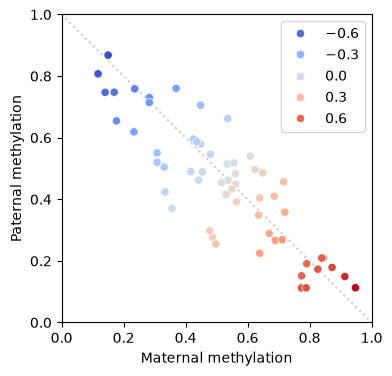

In [16]:
plt.figure(figsize=(4,4))
sns.scatterplot(data = df_wide, x = "Maternal", y = "Paternal", hue = "diff", palette = "coolwarm")
plt.ylim(0,1)
plt.xlim(0,1)

plt.ylabel("Paternal methylation")
plt.xlabel("Maternal methylation")

sns.lineplot(x=[0,1],y=[1,0], zorder = -1, color = "grey",linestyle=":", alpha = .4)

plt.savefig(f"{figure_dir}/hprc_xist_distribution.pdf")

In [18]:
df_wide.loc[df_wide['diff'] > 0, 'status'] = "MatXa"
df_wide.loc[df_wide['diff'] < 0, 'status'] = "PatXa"

df_wide.groupby('status').agg(count = ('sample','count')).reset_index()

,status,count
0,MatXa,34
1,PatXa,25


In [19]:
newdataset = pd.read_csv("/path/to/project/pooch/pooch_data/05.dss_using_123_pairing_chrX_balance/balance.sample.list", sep ='\t', header = None)
dss_sample = newdataset[0].to_list()

In [20]:
df_wide['dss'] = "not_used"
df_wide.loc[df_wide['sample'].isin(dss_sample), 'dss'] = "used"

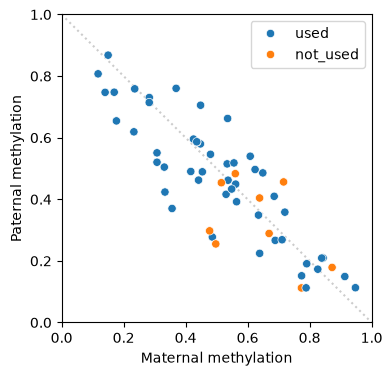

In [22]:
plt.figure(figsize=(4,4))
sns.scatterplot(data = df_wide, x = "Maternal", y = "Paternal", hue = "dss")
plt.ylim(0,1)
plt.xlim(0,1)

plt.ylabel("Paternal methylation")
plt.xlabel("Maternal methylation")

sns.lineplot(x=[0,1],y=[1,0], zorder = -1, color = "grey",linestyle=":", alpha = .4)
plt.savefig(f"{figure_dir}/hprc_xist_distribution_DSS.pdf")

In [23]:
df_wide.head(2)

hap,sample,id,Maternal,Paternal,diff,status,dss
0,HG00408,chrX:72285969-72286319,0.564417,0.392070,0.172347,MatXa,used
1,HG00423,chrX:72285969-72286319,0.447761,0.579832,-0.132071,PatXa,used


In [24]:
df_wide['new_dataset'] = "test"
n = 23
df_wide.loc[df_wide['sample'].isin(df_wide.loc[(df_wide['dss'] == "used") & (df_wide['status'] == "MatXa")].sample(n=n, random_state=0)['sample']).to_list(), 'new_dataset'] = "training"
df_wide.loc[df_wide['sample'].isin(df_wide.loc[(df_wide['dss'] == "used") & (df_wide['status'] == "PatXa")].sample(n=n, random_state=0)['sample']).to_list(), 'new_dataset'] = "training"
df_wide['new_dataset'] = pd.Categorical(df_wide['new_dataset'], categories=["training", "test"], ordered=True)

In [25]:
df_wide.groupby(['new_dataset', 'status']).size()

new_dataset  status
training     MatXa     23
             PatXa     23
test         MatXa     11
             PatXa      2
dtype: int64

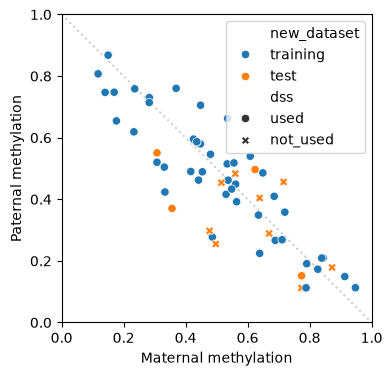

In [27]:
plt.figure(figsize=(4,4))
sns.scatterplot(data = df_wide, x = "Maternal", y = "Paternal", hue = "new_dataset", palette = ["#1f77b4", "#ff7f0e"], style = "dss")


plt.ylim(0,1)
plt.xlim(0,1)

plt.ylabel("Paternal methylation")
plt.xlabel("Maternal methylation")

sns.lineplot(x=[0,1],y=[1,0], zorder = -1, color = "grey",linestyle=":", alpha = .4)
plt.savefig(f"{figure_dir}/hprc_xist_distribution_DSS_model_training.pdf")

In [ ]:
df_wide.loc[df_wide['new_dataset'] == "training", "sample"].to_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46/balance_n46.training.sample.list", sep ='\t', index = False, header = False)
df_wide.loc[df_wide['new_dataset'] == "test", "sample"].to_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46/balance_n46.test.sample.list", sep ='\t', index = False, header = False)

In [15]:
df_wide.head(2)

hap,sample,id,Maternal,Paternal,diff,status,dss,new_dataset
0,HG00408,chrX:72285969-72286319,0.564417,0.392070,0.172347,MatXa,used,training
1,HG00423,chrX:72285969-72286319,0.447761,0.579832,-0.132071,PatXa,used,training


In [16]:
df_wide.loc[(df_wide['dss'] == "used") & (df_wide['status'] == "MatXa"), "sample"].to_csv("/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.models_using_DSS_insideCV/matXa_sample_25.list", sep ='\t', index = False, header = False)
df_wide.loc[(df_wide['dss'] == "used") & (df_wide['status'] == "PatXa"), "sample"].to_csv("/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.models_using_DSS_insideCV/patXa_sample_25.list", sep ='\t', index = False, header = False)